# 03 · Finding patterns and building a first SN Ia classifier

**Series:** Exploring the ZTF Bright Transient Survey to find Type Ia supernovae
1. Loading & cleaning with pandas
2. Visualising with matplotlib & seaborn
3. **Finding patterns & a first Ia classifier** ← you are here

---

Notebook 2 showed that SN Ia stand out in several ways: characteristic rise/fade times, location away from the Galactic plane, and uniform peak brightness. This notebook asks:

1. **Which features separate Ia from non-Ia, and by how much?**
2. **Which features can we actually use?** (The answer has a trap in it: *data leakage*.)
3. **How well does a simple machine-learning model do, and how should we measure that?**

The main library is **scikit-learn**, Python's standard machine-learning library. The goal is not the best possible model. It's a **correctly evaluated baseline** that later work can be compared against.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, f1_score,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

import ztf_style
from ztf_style import IA, INK, INK_2, MUTED, GRID, CLASS3_COLORS

ztf_style.use()
df = pd.read_parquet("data/bts_clean.parquet")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)   # 5-fold cross-validation, reused throughout

## 1 · Framing the problem

* **Target:** `is_ia`, True if the spectrum says SN Ia (including sub-types like 91T/91bg), otherwise False.
* **Unit of prediction:** one transient, described by its light-curve summary and sky position.
* **Training data:** objects that *have* a classification.

Notebook 1 found that 2026 objects have no types in this export even though many have been classified, so they get their own group. That gives three groups:

In [2]:
before_2026 = df["discdate"] < "2026-01-01"
labelled   = df[df["class3"].notna() & before_2026].copy()      # train / test on these
unlabelled = df[df["class3"].isna() & before_2026].copy()       # what we'd use the model on
recent     = df[~before_2026].copy()                            # 2026: classified, but types missing from export

pd.DataFrame({"objects": [len(labelled), len(unlabelled), len(recent)],
              "role": ["train & evaluate", "apply the model", "sanity check"]},
             index=["labelled (2018–2025)", "unlabelled (2018–2025)", "recent (2026)"])

,objects,role
labelled (2018–2025),7832,train & evaluate
unlabelled (2018–2025),3040,apply the model
recent (2026),332,sanity check


### Features

A few derived columns make things easier for the models:
* **log of the timescales**: they span 0.1 to 1,000 days, and a log makes "twice as long" the same step everywhere. A +1 avoids `log(0)`.
* **|b|**: distance from the Galactic plane matters, not which side of it.
* **peak_in_g**: whether the peak was in the g filter, as 0/1.
* the lower-limit flags as 0/1.

In [3]:
def add_features(d):
    d = d.copy()
    for col in ["rise", "fade", "duration"]:
        d[f"log_{col}"] = np.log10(d[col] + 1)
    d["abs_b"] = d["b"].abs()
    d["peak_in_g"] = (d["peakfilt"] == "g").astype(int)
    for col in ["rise_is_limit", "fade_is_limit", "duration_is_limit"]:
        d[col] = d[col].astype(int)
    return d


labelled, unlabelled, recent = (add_features(d) for d in (labelled, unlabelled, recent))
y = labelled["is_ia"].astype(bool).astype(int)          # 1 = SN Ia, 0 = not

PHOTOMETRIC = ["peakmag", "log_rise", "log_fade", "log_duration",
               "rise_is_limit", "fade_is_limit", "duration_is_limit",
               "peak_in_g", "abs_b", "A_V"]
NEEDS_REDSHIFT = ["redshift", "peakabs", "hostabs", "hostcol"]

print(f"Ia fraction among labelled objects: {y.mean():.1%}")

Ia fraction among labelled objects: 67.8%


## 2 · Patterns: how does the Ia fraction change with each feature?

A simple, powerful way to explore a binary target: split a feature into bins and plot **the fraction of Ia in each bin**. Where the line rises above the overall average, that value range is "Ia-like".

`pd.qcut` makes bins with *equal numbers of objects* (quantiles), so every point on the plot is based on the same amount of data.

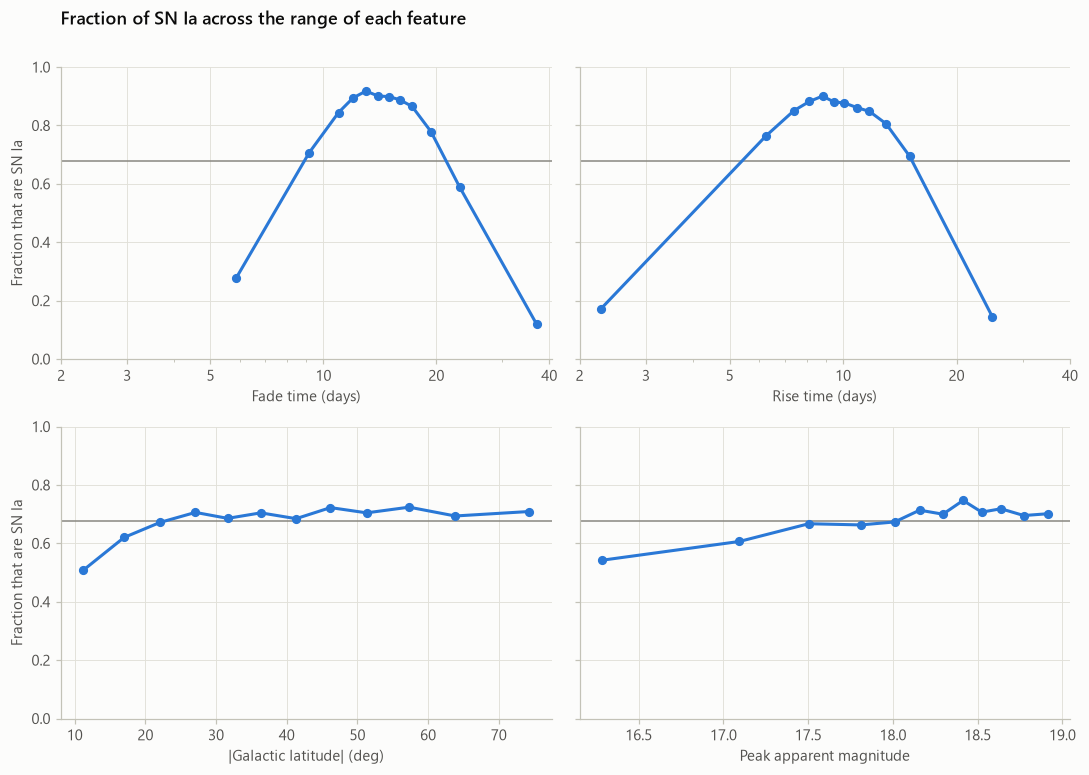

In [4]:
def ia_fraction_by_bin(frame, col, n_bins=12):
    bins = pd.qcut(frame[col], q=n_bins, duplicates="drop")
    g = frame.assign(is_ia=y).groupby(bins, observed=True)
    return pd.DataFrame({"x": g[col].median(), "ia_fraction": g["is_ia"].mean(), "n": g.size()})


panels = [("fade", "Fade time (days)", True), ("rise", "Rise time (days)", True),
          ("abs_b", "|Galactic latitude| (deg)", False), ("peakmag", "Peak apparent magnitude", False)]
measured = labelled[(labelled["rise_is_limit"] == 0) & (labelled["fade_is_limit"] == 0)]

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
for ax, (col, label, log_x) in zip(axes.flat, panels):
    source = measured if col in ("rise", "fade") else labelled
    t = ia_fraction_by_bin(source, col)
    ax.axhline(y.mean(), color=MUTED, linewidth=1)
    ax.plot(t["x"], t["ia_fraction"], color=IA, marker="o", markersize=5)
    if log_x:
        ax.set_xscale("log")
        ax.set_xticks([2, 3, 5, 10, 20, 40], labels=["2", "3", "5", "10", "20", "40"])
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel(label)
    ax.set_ylim(0, 1)
axes[0, 0].annotate(f"all labelled: {y.mean():.0%}", xy=(1.2, y.mean() + 0.03), color=INK_2, fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("Fraction that are SN Ia")
fig.suptitle("Fraction of SN Ia across the range of each feature", x=0.06, y=1.0, ha="left",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
ztf_style.save(fig, "03_ia_fraction_by_feature");

**What it shows:**
* **Fade time** is the strongest pattern: objects that fade by half in **~10–20 days are ~80–90% Ia**. Very fast faders (CVs) and very slow faders (SN II, SLSNe, AGN) are rarely Ia.
* **Rise time** shows a similar but weaker peak around ~8–12 days.
* **|b|**: close to the Galactic plane the Ia fraction drops, because Galactic CVs are common there.
* **Peak magnitude**: brighter objects are *less* likely to be Ia. The very brightest are nearby core-collapse SNe or Galactic CVs. This is a property of a magnitude-limited sample, not of Ia physics.

### Ranking features by separating power

How much can each feature tell us *on its own*? The yardstick is the **ROC AUC**: pick a random Ia and a random non-Ia, and ask how often the Ia gets the higher score.
* **0.5** means no information (a coin toss).
* **1.0** means perfect separation.

There are two ways to turn a single feature into a "score":
1. **Rank AUC**: use the feature value itself as the score. This only detects **monotonic** relationships, of the "more X → more Ia" kind.
2. **Single-feature model AUC**: train a small gradient-boosting model on just that one feature, cross-validated. This can also learn "Ia only in a middle range".

*(Strictly, this exploration uses all labelled objects, including the ones that will form the test set later. For quick exploration that's common, but a rigorous project would split first and explore the training set only.)*

,rank AUC,single-feature model AUC,needs redshift?
feature,,,
peakabs,0.814,0.922,True
redshift,0.768,0.868,True
log_duration,0.607,0.844,False
log_fade,0.580,0.805,False
log_rise,0.529,0.794,False
hostcol,0.643,0.738,True
hostabs,0.623,0.720,True
peak_in_g,0.577,0.577,False
duration_is_limit,0.576,0.576,False


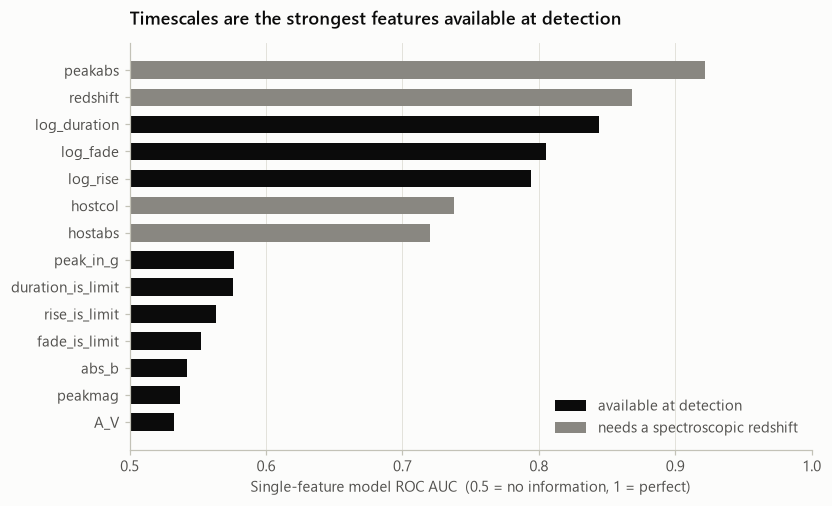

In [5]:
rows = []
for col in PHOTOMETRIC + NEEDS_REDSHIFT:
    ok = labelled[col].notna()
    rank_auc = roc_auc_score(y[ok], labelled.loc[ok, col])
    model_auc = cross_val_score(HistGradientBoostingClassifier(random_state=0), labelled[[col]], y,
                                cv=cv, scoring="roc_auc").mean()
    rows.append({"feature": col, "rank AUC": max(rank_auc, 1 - rank_auc), "single-feature model AUC": model_auc,
                 "needs redshift?": col in NEEDS_REDSHIFT})
single = pd.DataFrame(rows).sort_values("single-feature model AUC")

fig, ax = plt.subplots(figsize=(8, 4.8))
colors = [MUTED if leak else INK for leak in single["needs redshift?"]]
ax.barh(single["feature"], single["single-feature model AUC"] - 0.5, left=0.5, color=colors, height=0.65)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Single-feature model ROC AUC  (0.5 = no information, 1 = perfect)")
ax.grid(axis="y", visible=False)
ax.set_title("Timescales are the strongest features available at detection")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=INK, label="available at detection"),
                   Patch(color=MUTED, label="needs a spectroscopic redshift")], loc="lower right")
ztf_style.save(fig, "03_single_feature_auc");
single.sort_values("single-feature model AUC", ascending=False).set_index("feature").round(3)

**What it shows:**
* **The two measures disagree sharply for the timescales.** `log_fade` has a rank AUC of only ~0.58 but a model AUC of ~0.80. Section 2's plot explains it: Ia sit in a *sweet spot* of fade times, with fast and slow faders both non-Ia. Sorting by fade time puts Ia in the middle, not at one end, so rank AUC misses it. **A simple statistic can hide a strong but non-monotonic relationship. Always plot as well.**
* Among features available at detection, **duration, fade and rise** are by far the most informative. Position and brightness add only a little.
* The redshift-based features (grey), especially `peakabs`, look strong too. But they come with a serious catch, covered next.

## 3 · The trap: data leakage

**Data leakage** is when a model is trained on information that **would not be available at the moment you want to make a prediction**. A leaky model looks great when tested and then fails in real use.

Here's the use case: ZTF detects a new transient, and we want to decide **whether it's worth taking a spectrum** because it looks like a Ia. At that moment we have the light curve and the sky position. **We don't have a redshift.** That usually comes *from* the spectrum we're trying to decide whether to take.

The data confirms it. Redshift is essentially only known for objects that already have a classification:

In [6]:
pd.crosstab(df.loc[before_2026, "class3"].notna().map({True: "classified", False: "unclassified"}),
            df.loc[before_2026, "redshift"].notna().map({True: "has redshift", False: "no redshift"}))

redshift,has redshift,no redshift
class3,,
classified,7150,682
unclassified,0,3040


So:
* `redshift` comes from the classification spectrum, so it **leaks**.
* `peakabs` is computed from `redshift`, so it **leaks**.
* `hostabs` and `hostcol` are host-galaxy properties computed using the redshift, so they **leak** here. (In a real pipeline you could get a host galaxy's *photometric* redshift from a galaxy catalogue before taking a spectrum. That's a legitimate feature for future work.)
* Even **whether redshift is missing** leaks: "redshift is missing" almost means "unclassified".
* As notebook 1 found, the **IAU name prefix** (`SN...` vs `AT...`) leaks too.

**Rule of thumb:** for every feature, ask *"Would I know this at the moment I make the prediction?"*

The honest model therefore uses only the `PHOTOMETRIC` features. Section 7 builds a leaky model on purpose, to show how misleading it is.

## 4 · Train / test split

A model has to be evaluated on data it has **never seen**. We set aside 25% of the labelled objects as a **test set** and don't touch it until the end.
* `stratify=y` keeps the Ia fraction the same in both parts.
* `random_state` makes the split reproducible.

During development, we estimate performance with **cross-validation** on the training set only. The training set is split into 5 parts; the model trains on 4 and is scored on the 5th, rotating through all five.

In [7]:
X = labelled[PHOTOMETRIC]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"train: {len(X_train):,} objects  ({y_train.mean():.1%} Ia)")
print(f"test:  {len(X_test):,} objects  ({y_test.mean():.1%} Ia)")

train: 5,874 objects  (67.8% Ia)
test:  1,958 objects  (67.8% Ia)


## 5 · Three models

| Model | Idea |
|---|---|
| **Dummy** | Always predicts the majority class. This is the **baseline** a real model must beat. |
| **Logistic regression** | A weighted sum of features, squashed into a probability. Simple and interpretable. |
| **Gradient-boosted trees** | Hundreds of small decision trees, each correcting the previous ones' mistakes. Captures non-linear patterns, like "Ia-like only if fade is *between* 10 and 20 days". |

Logistic regression needs every feature to have a value (no NaN) and on a similar scale, so it goes into a **pipeline**: *fill missing values → standardise → fit*. A pipeline makes sure the filling and scaling are learned **only from the training data**, which avoids a subtle form of leakage. `HistGradientBoostingClassifier` handles missing values on its own.

In [8]:
models = {
    "Dummy (always 'Ia')": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(max_iter=1000)),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=0),
}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name:22s} cross-validated ROC AUC = {scores.mean():.3f} ± {scores.std():.3f}")

Dummy (always 'Ia')    cross-validated ROC AUC = 0.500 ± 0.000
Logistic regression    cross-validated ROC AUC = 0.715 ± 0.024


Gradient boosting      cross-validated ROC AUC = 0.881 ± 0.006


Both real models beat the dummy (AUC 0.5), but **gradient boosting beats logistic regression by a wide margin**. It's the sweet-spot problem again. Logistic regression can only learn "more X → more Ia" (or less), and can't represent "Ia-like only when fade is between 10 and 20 days". Trees can. *(Exercise idea: give logistic regression squared features and see how much of the gap closes.)*

Now each model is fitted on the full training set and evaluated **once** on the test set.

In [9]:
def evaluate(name, model, X_eval, y_eval, threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_eval, pred),
            "ROC AUC": roc_auc_score(y_eval, proba),
            "purity (precision)": precision_score(y_eval, pred, zero_division=0),
            "completeness (recall)": recall_score(y_eval, pred),
            "F1": f1_score(y_eval, pred)}


results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append(evaluate(name, model, X_test, y_test))
pd.DataFrame(results).set_index("model").round(3)

,accuracy,ROC AUC,purity (precision),completeness (recall),F1
model,,,,,
Dummy (always 'Ia'),0.678,0.500,0.678,1.000,0.808
Logistic regression,0.740,0.703,0.743,0.942,0.831
Gradient boosting,0.854,0.902,0.856,0.944,0.898


### Reading these metrics as an astronomer

At the default threshold of 0.5, the model labels an object "Ia" if it thinks the probability is above 50%.

* **Accuracy**: the fraction of all objects labelled correctly. **Misleading on its own:** the dummy gets 68% while knowing nothing.
* **Purity (precision)**: of the objects we *call* Ia, what fraction really are? Low purity wastes telescope time on spectra of non-Ia, and contaminates a cosmology sample.
* **Completeness (recall)**: of all the *real* Ia, what fraction did we find? Low completeness means missing Ia.
* **F1**: a single number balancing purity and completeness.
* **ROC AUC**: threshold-free. It measures how well the model *ranks* Ia above non-Ia.

The dummy has 100% completeness (it calls everything Ia) with only 68% purity. Gradient boosting raises purity substantially while keeping completeness high.

## 6 · Looking closer at the gradient-boosting model

### Confusion matrix

This shows exactly where the model goes wrong: rows are the truth, columns are the prediction.

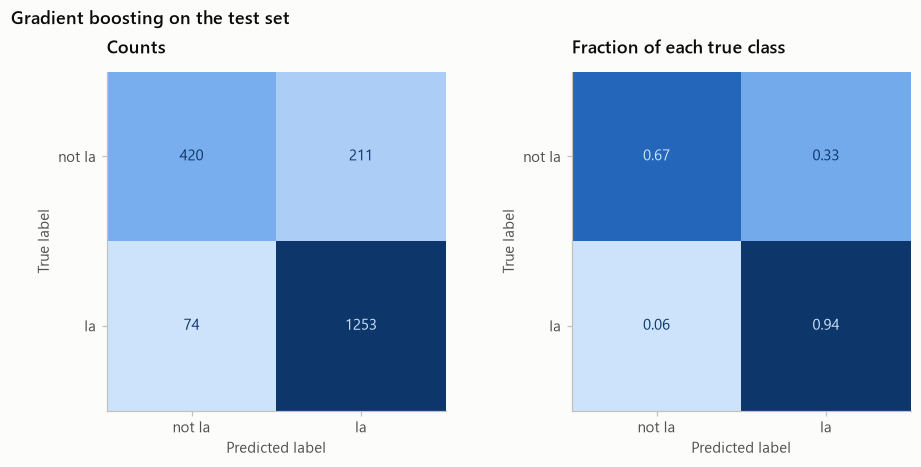

In [10]:
gb = models["Gradient boosting"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, normalize, title in zip(axes, [None, "true"], ["Counts", "Fraction of each true class"]):
    ConfusionMatrixDisplay.from_estimator(gb, X_test, y_test, display_labels=["not Ia", "Ia"],
                                          normalize=normalize, cmap="ztf_blues", colorbar=False,
                                          values_format=".0f" if normalize is None else ".2f", ax=ax)
    ax.grid(False)
    ax.set_title(title)
fig.suptitle("Gradient boosting on the test set", x=0.06, y=1.02, ha="left", fontsize=12, fontweight="semibold")
ztf_style.save(fig, "03_confusion_matrix");

Most errors are **non-Ia called Ia** (bottom-left of each matrix is small, top-right is larger): the model is generous with the Ia label. That's expected, since Ia are the majority and other SNe often have similar timescales. Which non-Ia get confused most?

In [11]:
test_rows = labelled.loc[X_test.index].assign(p_ia=gb.predict_proba(X_test)[:, 1])
(test_rows[test_rows["is_ia"] == False]
    .groupby("subclass")
    .agg(n=("p_ia", "size"), called_Ia=("p_ia", lambda p: (p >= 0.5).mean()), median_p_ia=("p_ia", "median"))
    .sort_values("n", ascending=False)
    .round(2))

,n,called_Ia,median_p_ia
subclass,,,
SN II,295,0.35,0.17
CV / nova,136,0.05,0.02
SN Ib/c,101,0.77,0.73
AGN,54,0.20,0.02
SLSN,24,0.12,0.01
SN peculiar,11,0.82,0.76
TDE,8,0.12,0.01
Other,2,0.00,0.22


Stripped-envelope SNe (**SN Ib/c**) are the most often mistaken for Ia. They have similar light-curve shapes, and astronomers know they're hard to separate from photometry alone. CVs and AGN, with very different timescales, are rarely confused.

### ROC and precision–recall curves

The 0.5 threshold is arbitrary. These curves show the model's performance at **every** threshold:
* The **ROC curve** plots the true-positive rate against the false-positive rate.
* The **precision–recall curve** plots purity against completeness, the trade-off astronomers actually care about.

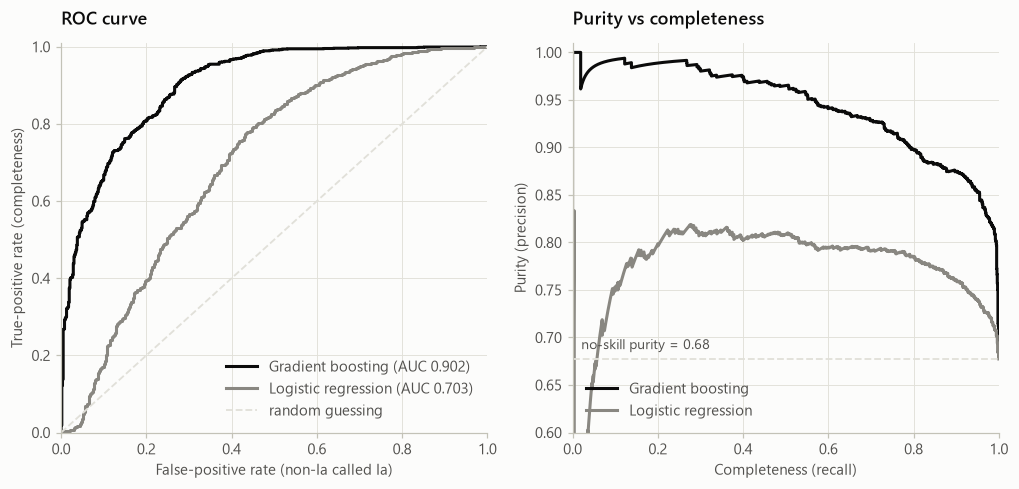

In [12]:
lr = models["Logistic regression"]
curve_styles = {"Gradient boosting": (gb, INK), "Logistic regression": (lr, MUTED)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
for name, (model, color) in curve_styles.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ax1.plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")
    ax2.plot(rec, prec, color=color, label=name)
ax1.plot([0, 1], [0, 1], color=GRID, linewidth=1.2, linestyle="--", label="random guessing")
ax1.set(xlabel="False-positive rate (non-Ia called Ia)", ylabel="True-positive rate (completeness)",
        title="ROC curve", xlim=(0, 1), ylim=(0, 1.01))
ax1.legend(loc="lower right")
ax2.axhline(y_test.mean(), color=GRID, linewidth=1.2, linestyle="--")
ax2.annotate(f"no-skill purity = {y_test.mean():.2f}", xy=(0.02, y_test.mean() + 0.01), color=INK_2, fontsize=9)
ax2.set(xlabel="Completeness (recall)", ylabel="Purity (precision)", title="Purity vs completeness",
        xlim=(0, 1), ylim=(0.6, 1.01))
ax2.legend(loc="lower left")
ztf_style.save(fig, "03_roc_pr_curves");

### Choosing a threshold for a real use case

Say we want a list of Ia candidates for spectroscopy that is **≥ 95% pure**. What threshold gives that, and what completeness does it cost?

The threshold must be chosen **without looking at the test set**, or the test set stops being an honest check. So we use `cross_val_predict` to get *out-of-fold* probabilities for the training set. Each one comes from a model that didn't see that object.

In [13]:
oof = cross_val_predict(HistGradientBoostingClassifier(random_state=0), X_train, y_train, cv=cv,
                        method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
target_purity = 0.95
idx = np.argmax(prec[:-1] >= target_purity)           # first threshold reaching the target purity
threshold_95 = thr[idx]
print(f"Threshold chosen on training data: P(Ia) ≥ {threshold_95:.2f}")

pd.DataFrame([evaluate("GB @ 0.50", gb, X_test, y_test, 0.5),
              evaluate(f"GB @ {threshold_95:.2f}", gb, X_test, y_test, threshold_95)]).set_index("model").round(3)

Threshold chosen on training data: P(Ia) ≥ 0.95


,accuracy,ROC AUC,purity (precision),completeness (recall),F1
model,,,,,
GB @ 0.50,0.854,0.902,0.856,0.944,0.898
GB @ 0.95,0.557,0.902,0.975,0.356,0.521


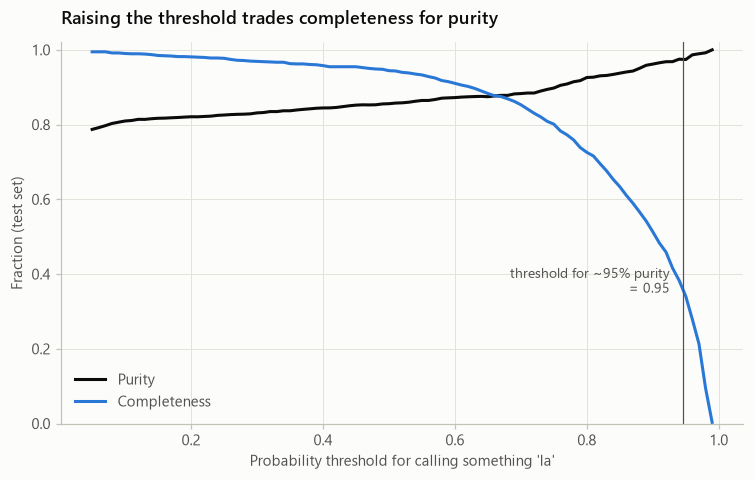

In [14]:
grid = np.linspace(0.05, 0.99, 95)
p_test = gb.predict_proba(X_test)[:, 1]
purity = [precision_score(y_test, p_test >= t, zero_division=1) for t in grid]
completeness = [recall_score(y_test, p_test >= t) for t in grid]

fig, ax = plt.subplots()
ax.plot(grid, purity, color=INK, label="Purity")
ax.plot(grid, completeness, color=IA, label="Completeness")
ax.axvline(threshold_95, color=INK_2, linewidth=0.8)
ax.annotate(f"threshold for ~95% purity\n= {threshold_95:.2f}", xy=(threshold_95 - 0.02, 0.35), ha="right",
            color=INK_2, fontsize=9)
ax.set(xlabel="Probability threshold for calling something 'Ia'", ylabel="Fraction (test set)", ylim=(0, 1.02),
       title="Raising the threshold trades completeness for purity")
ax.legend(loc="lower left")
ztf_style.save(fig, "03_threshold_tradeoff");

**The takeaway:** there's no single "accuracy" for a classifier, only a trade-off. A cosmology project wanting a clean Ia sample would pick a high threshold. A project that doesn't want to miss *any* Ia would pick a low one. **The science goal decides the threshold.**

### Which features does the model rely on?

**Permutation importance:** shuffle one feature's values in the test set and measure how much the ROC AUC drops. A big drop means the model depends on that feature.

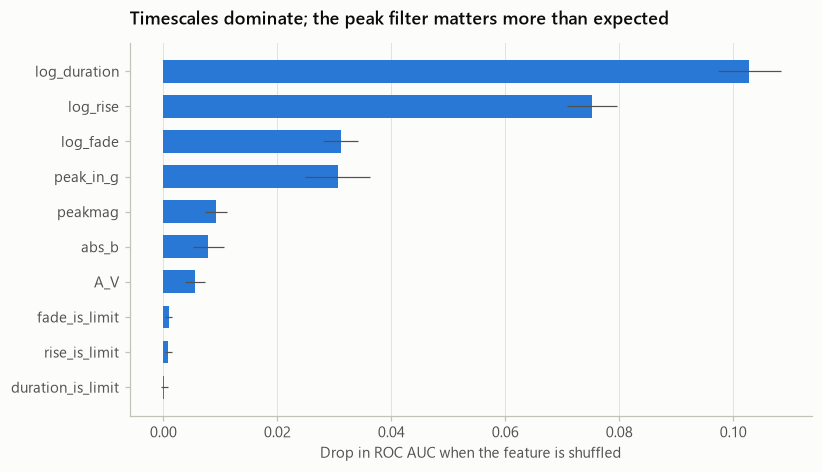

In [15]:
perm = permutation_importance(gb, X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=0)
importance = pd.Series(perm.importances_mean, index=PHOTOMETRIC).sort_values()
errors = pd.Series(perm.importances_std, index=PHOTOMETRIC)[importance.index]

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(importance.index, importance.values, xerr=errors.values, color=IA, height=0.65,
        error_kw=dict(ecolor=INK_2, elinewidth=0.8, capsize=0))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Drop in ROC AUC when the feature is shuffled")
ax.set_title("Timescales dominate; the peak filter matters more than expected")
ztf_style.save(fig, "03_permutation_importance");

* The model leans mostly on the **light-curve timescales** (duration, rise and fade). That matches the patterns in section 2, which is reassuring: it has learned something physically sensible.
* **`peak_in_g` matters surprisingly much.** It records which filter the peak was measured in. If that's the filter where the object was brighter, then `peak_in_g = 1` means the object was relatively *blue* at peak, making it a crude **colour** indicator. That hints that proper colour information would be a valuable feature (see next steps).
* Peak magnitude, |b| and extinction add a little. The limit flags add almost nothing *on top of* the timescale values themselves.

## 7 · Demonstration: what a leaky model looks like

Now let's do the *wrong* thing on purpose: add `redshift`, `peakabs`, `hostabs` and `hostcol`.

In [16]:
X_leaky = labelled[PHOTOMETRIC + NEEDS_REDSHIFT]
Xl_train, Xl_test = X_leaky.loc[X_train.index], X_leaky.loc[X_test.index]   # same split as before
gb_leaky = HistGradientBoostingClassifier(random_state=0).fit(Xl_train, y_train)

pd.DataFrame([evaluate("Honest (photometric only)", gb, X_test, y_test),
              evaluate("Leaky (+ redshift features)", gb_leaky, Xl_test, y_test)]).set_index("model").round(3)

,accuracy,ROC AUC,purity (precision),completeness (recall),F1
model,,,,,
Honest (photometric only),0.854,0.902,0.856,0.944,0.898
Leaky (+ redshift features),0.943,0.977,0.951,0.965,0.958


The leaky model looks much better. **It's a mirage:** it relies on `peakabs`, which needs a spectrum we won't have when the prediction is needed. If someone shows you a supernova classifier with suspiciously high accuracy, the first question to ask is **"which features did it use, and when would those be known?"**

(Redshift and `peakabs` *are* useful in a different setting: classifying objects with a host-galaxy redshift from a catalogue, or a photometric-redshift estimate. Building that would be a good follow-up project.)

## 8 · A more honest test: train on the past, predict the future

A random split mixes objects from every year into both training and test sets. In real use, a model trained on **past** data is applied to **future** transients. Survey conditions, software and follow-up priorities change over time, so a time-based split is a stricter test.

In [17]:
train_past = labelled["discdate"] < "2024-01-01"
test_future = ~train_past                                      # 2024–2025
gb_time = HistGradientBoostingClassifier(random_state=0).fit(labelled.loc[train_past, PHOTOMETRIC], y[train_past])

pd.DataFrame([evaluate("Random split (from above)", gb, X_test, y_test),
              evaluate("Train 2018–2023 → test 2024–2025", gb_time,
                       labelled.loc[test_future, PHOTOMETRIC], y[test_future])]).set_index("model").round(3)

,accuracy,ROC AUC,purity (precision),completeness (recall),F1
model,,,,,
Random split (from above),0.854,0.902,0.856,0.944,0.898
Train 2018–2023 → test 2024–2025,0.823,0.845,0.859,0.908,0.883


**Performance drops:** ROC AUC falls from ~0.90 to ~0.85 when predicting future years. The obvious suspicion is that the world changed after training. Let's check whether the features look different over time:

,rise_is_limit,fade_is_limit
discdate,,
2018,0.17,0.20
2019,0.08,0.12
2020,0.04,0.08
2021,0.04,0.10
2022,0.34,0.13
2023,0.36,0.13
2024,0.43,0.15
2025,0.40,0.15


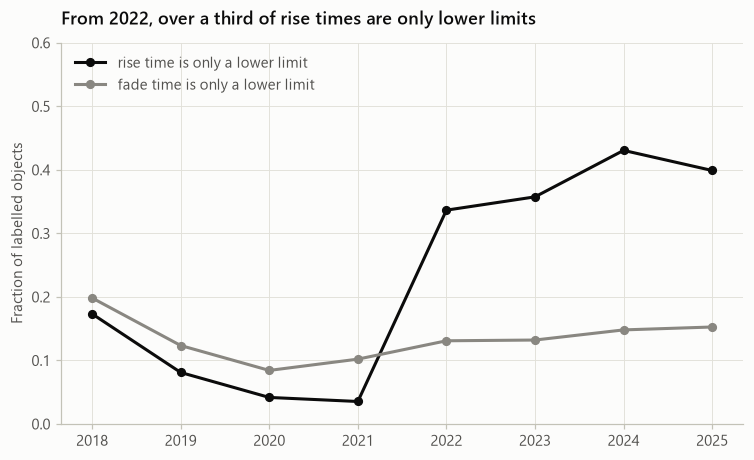

In [18]:
by_year = labelled.groupby(labelled["discdate"].dt.year)[["rise_is_limit", "fade_is_limit"]].mean().loc[2018:]

fig, ax = plt.subplots()
ax.plot(by_year.index, by_year["rise_is_limit"], color=INK, marker="o", markersize=5, label="rise time is only a lower limit")
ax.plot(by_year.index, by_year["fade_is_limit"], color=MUTED, marker="o", markersize=5, label="fade time is only a lower limit")
ax.set_ylim(0, 0.6)
ax.set_ylabel("Fraction of labelled objects")
ax.set_title("From 2022, over a third of rise times are only lower limits")
ax.legend(loc="upper left")
ztf_style.save(fig, "03_feature_drift");
by_year.round(2)

**Found it.** In 2019–2021 only ~4–8% of rise times were lower limits. From 2022 it's **~35–45%**. Something changed around the start of 2022, right after the near-total gap in discoveries in December 2021 to February 2022 seen in notebook 2. The survey's observing pattern or the way rise times are measured changed, so for most recent objects **we no longer know the rise time precisely**. A change like this in how the data is generated is called **data drift**.

Is the model failing because it was trained on the "old" regime, or are recent objects simply harder? One test: cross-validate *within* each era separately.

In [19]:
year = labelled["discdate"].dt.year
eras = {"2019–2021": (year >= 2019) & (year <= 2021), "2024–2025": year >= 2024}
pd.DataFrame([{"era": name, "objects": int(mask.sum()),
               "ROC AUC (cross-validated within era)":
                   cross_val_score(HistGradientBoostingClassifier(random_state=0), labelled.loc[mask, PHOTOMETRIC],
                                   y[mask], cv=cv, scoring="roc_auc").mean()}
              for name, mask in eras.items()]).set_index("era").round(3)

,objects,ROC AUC (cross-validated within era)
era,,
2019–2021,3828,0.893
2024–2025,1791,0.833


Even a model trained *and* tested only on 2024–2025 data does worse than one working on 2019–2021 data. So the drop is mainly because **recent objects carry less information** (a lower limit on rise time says less than a measured rise time), not because the model is out of date.

**Lessons:**
* A random split can **overestimate** future performance. The time-split number (~0.85) is the more honest estimate for new data.
* **Plot your features over time.** Pipeline and survey changes leave fingerprints in the data.
* For this dataset, better light-curve information (next steps below) matters more than a fancier model.

## 9 · Applying the model to objects without labels

### Sanity check with the 2026 objects

The 2026 objects have no types in this file, but their IAU names carry a hint: `SN...` means a spectrum confirmed a supernova. The idea is to compare how the model treats 2026 objects with how it treats labelled objects carrying the same prefix.

For the labelled objects we need predictions from models that **did not train on them**, so we use out-of-fold predictions again. For 2026 we use a final model trained on all labelled data.

In [20]:
final_model = HistGradientBoostingClassifier(random_state=0).fit(labelled[PHOTOMETRIC], y)   # use ALL labelled data

labelled["p_ia_oof"] = cross_val_predict(HistGradientBoostingClassifier(random_state=0), labelled[PHOTOMETRIC], y,
                                         cv=cv, method="predict_proba")[:, 1]
recent["p_ia"] = final_model.predict_proba(recent[PHOTOMETRIC])[:, 1]


def called_ia(frame, col):
    return (frame.groupby(frame["IAUID"].str[:2])[col]
                 .agg(n="size", called_Ia=lambda p: (p >= 0.5).mean()))


pd.concat({"labelled 2018–2025": called_ia(labelled, "p_ia_oof"), "recent 2026": called_ia(recent, "p_ia")},
          axis=1).loc[["AT", "SN"]].round(2)

labelled 2018–2025           recent 2026          
                       n called_Ia           n called_Ia
IAUID                                                   
AT                   789      0.16       108.0      0.76
SN                  6990      0.82       224.0      0.69

This check **didn't work out as hoped**, and the reasons are instructive:

* **`SN`-named objects:** 82% are called Ia among the labelled data (about 75% of supernovae there really are Ia), but only ~69% in 2026. The 2026 light curves are **still incomplete**: many haven't finished fading, so a third of their fade times are only lower limits (see below). The model has less to go on.
* **`AT`-named objects:** among labelled objects, `AT` almost always means "not a supernova" (CVs, AGN), and only ~16% are called Ia. In 2026, `AT` mostly means **"not classified *yet*"**: a mix that includes plenty of real supernovae, so far more are called Ia.

**Lesson:** a sanity check needs a reference whose meaning doesn't change. When a check fails, examine the *check* as well as the model. Here the label "AT" meant different things in different years.

In [21]:
pd.DataFrame({"labelled 2018–2025": labelled[["rise_is_limit", "fade_is_limit"]].mean(),
              "recent 2026": recent[["rise_is_limit", "fade_is_limit"]].mean()}).round(2)

,labelled 2018–2025,recent 2026
rise_is_limit,0.21,0.45
fade_is_limit,0.13,0.33


### The unclassified objects (2018–2025)

Before trusting predictions on the unclassified objects, check whether they **look like** the training data. If they don't, the model is being asked to *extrapolate*.

,labelled,unclassified
peakmag,18.23,18.79
rise,9.55,9.01
fade,14.48,13.96
abs_b,39.05,38.99


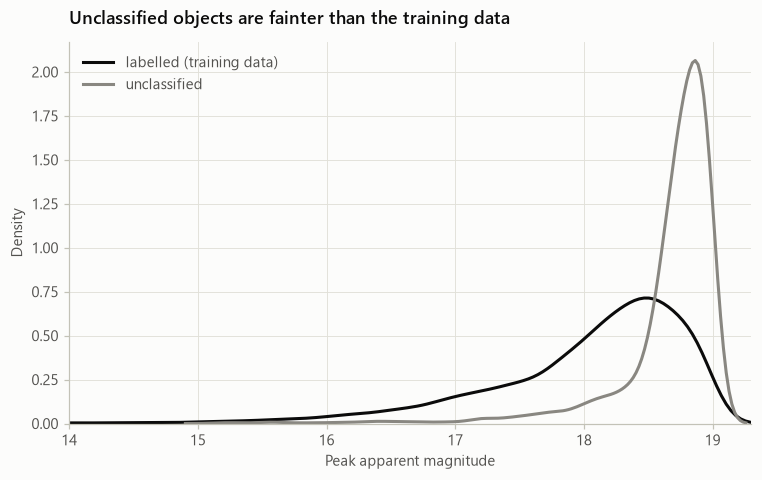

In [22]:
fig, ax = plt.subplots()
sns.kdeplot(labelled["peakmag"], ax=ax, color=INK, linewidth=2, label="labelled (training data)")
sns.kdeplot(unlabelled["peakmag"], ax=ax, color=MUTED, linewidth=2, label="unclassified")
ax.set_xlim(14, 19.3)
ax.set_xlabel("Peak apparent magnitude")
ax.set_title("Unclassified objects are fainter than the training data")
ax.legend(loc="upper left")
ztf_style.save(fig, "03_distribution_shift");

pd.DataFrame({"labelled": labelled[["peakmag", "rise", "fade", "abs_b"]].median(),
              "unclassified": unlabelled[["peakmag", "rise", "fade", "abs_b"]].median()}).round(2)

The unclassified objects are mostly **fainter**: they're the ones too faint for easy spectroscopy. The training set contains plenty of objects at those magnitudes, so the model isn't extrapolating badly. But fainter objects also have **noisier light curves**, so expect lower real-world performance on them than the test-set scores suggest. This mismatch is called **distribution shift**.

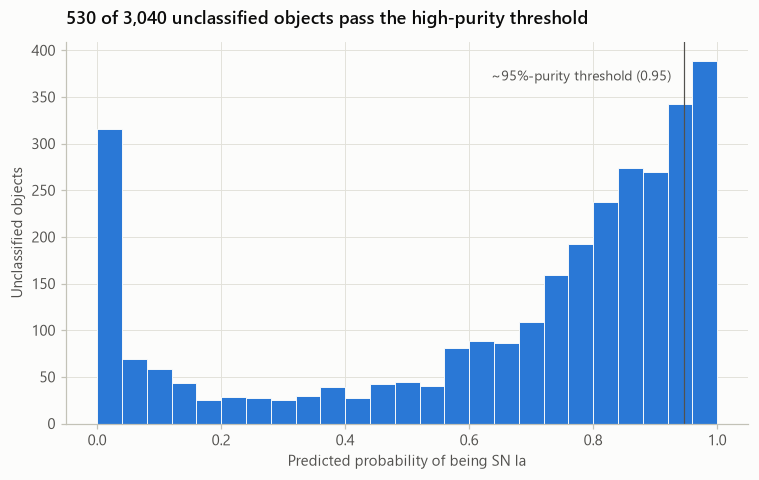

In [23]:
unlabelled["p_ia"] = final_model.predict_proba(unlabelled[PHOTOMETRIC])[:, 1]

fig, ax = plt.subplots()
ax.hist(unlabelled["p_ia"], bins=np.linspace(0, 1, 26), color=IA, edgecolor=ztf_style.SURFACE, linewidth=0.6)
ax.axvline(threshold_95, color=INK_2, linewidth=0.8)
ax.annotate(f"~95%-purity threshold ({threshold_95:.2f})", xy=(threshold_95 - 0.02, ax.get_ylim()[1] * 0.9),
            ha="right", color=INK_2, fontsize=9)
ax.set_xlabel("Predicted probability of being SN Ia")
ax.set_ylabel("Unclassified objects")
n_conf = (unlabelled["p_ia"] >= threshold_95).sum()
ax.set_title(f"{n_conf:,} of {len(unlabelled):,} unclassified objects pass the high-purity threshold")
ztf_style.save(fig, "03_unclassified_predictions");

In [24]:
cols = ["ZTFID", "IAUID", "discdate", "peakmag", "rise", "fade", "abs_b", "p_ia"]
(unlabelled.sort_values("p_ia", ascending=False)[cols].head(10)
           .assign(discdate=lambda d: d["discdate"].dt.date)
           .round({"peakmag": 2, "rise": 1, "fade": 1, "abs_b": 1, "p_ia": 3}))

,ZTFID,IAUID,discdate,peakmag,rise,fade,abs_b,p_ia
10658,ZTF25acaties,AT2025abyj,2025-10-30,18.50,11.3,13.9,12.6,0.994
9514,ZTF24abwevju,AT2024adsq,2024-12-09,18.89,12.9,13.0,65.0,0.993
8940,ZTF24aawavgt,AT2024pwi,2024-07-22,18.85,10.8,13.9,21.6,0.993
6362,ZTF22aandowy,AT2022mcs,2022-06-06,18.90,8.1,12.5,28.6,0.991
5337,ZTF21abidqoe,AT2021rbo,2021-07-05,18.89,13.7,7.9,20.3,0.991
10413,ZTF25ablzfdm,AT2025vlv,2025-08-26,18.89,8.9,12.1,15.0,0.990
3524,ZTF20aboueja,AT2020qia,2020-07-22,18.94,8.2,14.9,22.7,0.990
4845,ZTF21aaqkqwq,AT2021gtd,2021-03-28,18.71,8.8,14.0,24.2,0.990
3426,ZTF20abjksgj,AT2020odi,2020-07-02,18.82,8.7,15.8,24.5,0.989
3836,ZTF20acglhmw,AT2020usu,2020-10-08,18.87,11.3,12.0,31.4,0.989


These are the model's most confident Ia candidates among the unclassified objects. **Exercise:** look a few of them up on the Transient Name Server (wis-tns.org) or a ZTF alert broker (ALeRCE, Fink, Lasair) to see whether a classification exists elsewhere.

## Summary: what I learned

**About machine learning**
* **Start with a baseline.** A classifier that always says "Ia" is 68% accurate here, so accuracy alone means little.
* **Watch for leakage.** Redshift, absolute magnitude, host properties derived from redshift, and even the IAU name all encode the answer. Only use what is known *at prediction time*.
* **Evaluate honestly:** hold out a test set, use cross-validation for every decision, choose thresholds on out-of-fold predictions, and try a time-based split.
* **Simple statistics can mislead.** Fade time looks weak by rank AUC but is the strongest feature. Its relationship with "Ia" is a sweet spot, not a straight line, which is also why trees beat logistic regression here.
* **Plot features over time.** A survey or pipeline change in 2022 made rise times much less informative. This is *data drift*.
* **Purity vs completeness** (precision vs recall) is a trade-off, and the science goal picks the threshold.
* **Check what the model relies on** (permutation importance) and whether it makes physical sense.
* **Check for distribution shift** before applying a model to new data.

**About Type Ia supernovae in ZTF**
* Using only **light-curve timescales, peak brightness and sky position**, gradient boosting separates Ia from non-Ia with ROC AUC ≈ 0.90 on a random test split, and ≈ 0.85 when predicting future years.
* At the default threshold that's ~86% purity at ~94% completeness. Pushing purity to ~97% costs most of the completeness (~36%).
* **Light-curve timescales** (duration, fade, rise) carry most of the information. Ia fade by half in roughly 10–20 days.
* The hardest confusion is **SN Ia vs SN Ib/c**, a known problem in the field.

## Limitations and next steps
1. **Use full light curves, not summaries.** Brightness measurements over time, in both g and r filters, contain much more information: colour, colour evolution, light-curve shape. These are available from ZTF alert brokers (ALeRCE, Fink, Lasair) and the ZTF forced-photometry service. State-of-the-art classifiers use them.
2. **Colour features.** Ia have characteristic g−r colours around peak, and this table doesn't include colour.
3. **Host-galaxy information from catalogues** (photometric redshifts, galaxy type) is a *legitimate* way to add some of what the leaky features carried.
4. **Tune the model** with `GridSearchCV` / `RandomizedSearchCV`, and **calibrate** the probabilities (`CalibratedClassifierCV`) so that "0.8" really means 80%.
5. **Multi-class classification** (Ia / II / Ib/c / SLSN / ...) instead of yes/no.
6. **Early classification.** For spectroscopic follow-up, the decision is needed *before* peak, using only the first few days of data. That's a much harder and more useful problem.

## Exercises
1. Add `class_weight="balanced"` to the logistic regression. How do purity and completeness change, and why?
2. Remove `peakmag` from `PHOTOMETRIC` and retrain. How much does performance drop?
3. Train a model to separate **SN Ia from SN Ib/c only**. What ROC AUC do you get? Which features matter most?
4. Replace `HistGradientBoostingClassifier` with `RandomForestClassifier` (it needs the imputer pipeline). Does it do better or worse?
5. Change the time split to "train ≤ 2021, test 2022–2025". Does performance hold up?